In [ ]:
# 07 — Average Room Temperature Modeling
Goal: Predict the average temperature of all 48 sensors 60 minutes ahead, and simulate energy savings.

In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. Load Data
aau = pd.read_csv(r"D:\Projects\datacenter-efficiencyDMP\data\raw\AAU_temperature_and_power_use.csv")
aau['Time [Date/Time]'] = pd.to_datetime(aau['Time [Date/Time]'])

# 2. Identify ALL temperature columns
temp_cols = [c for c in aau.columns if c.startswith('Temperature')]

# 3. Create the "Average Room Temp" (Mean of all 48 sensors)
aau['Room_Avg_Temp'] = aau[temp_cols].mean(axis=1)

# Keep only time, the average, and power
cols_to_keep = ['Time [Date/Time]', 'Room_Avg_Temp', 'Power Ch 1 (W)', 'Power Ch 2 (W)', 'Power Ch 3 (W)']
df = aau[cols_to_keep].copy()

# 4. Downsample to 1 minute
df = df.set_index('Time [Date/Time]').resample('1min').mean().reset_index()
df = df.rename(columns={
    'Time [Date/Time]': 'time', 
    'Room_Avg_Temp': 'temp',
    'Power Ch 1 (W)': 'power_1', 'Power Ch 2 (W)': 'power_2', 'Power Ch 3 (W)': 'power_3'
})

print("Avg room temp range:", df['temp'].min(), "to", df['temp'].max(), "°C")

Avg room temp range: 23.883178703125 to 28.906149502430555 °C


In [2]:
# Time features
df['hour'] = df['time'].dt.hour
df['minute'] = df['time'].dt.minute
df['regime'] = (df['time'] >= '2024-09-28').astype(int)

# Target: 60 min ahead
df['temp_target_60m'] = df['temp'].shift(-60)

# Lags
df['temp_lag_1m']  = df['temp'].shift(1)
df['temp_lag_5m']  = df['temp'].shift(5)
df['temp_lag_15m'] = df['temp'].shift(15)
df['temp_lag_60m'] = df['temp'].shift(60)
df['power_1_lag_1m'] = df['power_1'].shift(1)
df['power_1_lag_5m'] = df['power_1'].shift(5)
df['temp_rolling_mean_15m'] = df['temp'].rolling(window=15).mean()

df_clean = df.dropna().reset_index(drop=True)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000513 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2634
[LightGBM] [Info] Number of data points in the train set: 16202, number of used features: 12
[LightGBM] [Info] Start training from score 26.253455
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

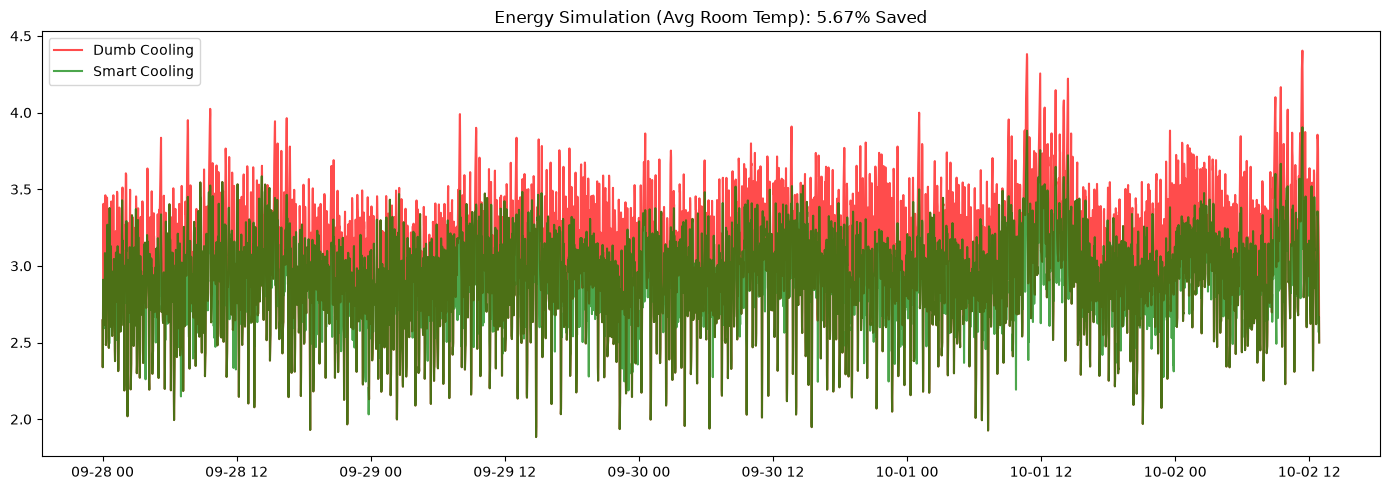

In [3]:
split_date = pd.to_datetime('2024-09-28')
train = df_clean[df_clean['time'] < split_date]
test  = df_clean[df_clean['time'] >= split_date]

features = ['power_1', 'power_2', 'power_3', 'hour', 'minute', 'regime', 
            'temp_lag_1m', 'temp_lag_5m', 'temp_lag_15m', 'temp_lag_60m', 
            'power_1_lag_1m', 'power_1_lag_5m', 'temp_rolling_mean_15m']

X_train, y_train = train[features], train['temp_target_60m']
X_test, y_test = test[features], test['temp_target_60m']

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=7, random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, predictions)
baseline_mae = mean_absolute_error(y_test, test['temp'])
print(f"Avg Room 60-Min MAE: {mae:.3f} °C")
print(f"Avg Room Baseline MAE: {baseline_mae:.3f} °C")

# --- ENERGY SIMULATION ---
results = pd.DataFrame({
    'time': test['time'].values,
    'actual_temp': y_test.values,
    'predicted_temp': predictions
})

# Baseline: Keep room at 22.0°C
baseline_energy = (results['actual_temp'] - 22.0).clip(lower=1.0)

# Smart: Relax target if we predict a drop
smart_energy = []
for i in range(len(results)):
    if results['predicted_temp'].iloc[i] < results['actual_temp'].iloc[i]:
        current_target = 22.5 
    else:
        current_target = 22.0
    energy = max(1.0, results['actual_temp'].iloc[i] - current_target)
    smart_energy.append(energy)

results['baseline_energy'] = baseline_energy
results['smart_energy'] = smart_energy

savings = ((results['baseline_energy'].sum() - sum(smart_energy)) / results['baseline_energy'].sum()) * 100
print(f"NEW Energy Saved: {savings:.2f}%")

# Plot
plt.figure(figsize=(14, 5))
plt.plot(results['time'], results['baseline_energy'], label='Dumb Cooling', color='red', alpha=0.7)
plt.plot(results['time'], smart_energy, label='Smart Cooling', color='green', alpha=0.7)
plt.title(f'Energy Simulation (Avg Room Temp): {savings:.2f}% Saved')
plt.legend()
plt.tight_layout()
plt.savefig(r"D:\Projects\datacenter-efficiencyDMP\reports\figures\07_avg_room_energy.png", dpi=150)
plt.show()

In [ ]:
# 05 — Industry-Style Non-Linear Energy Simulation
In real HVAC systems, energy consumption does not scale linearly.
It scales quadratically (exponentially) the further the room temperature deviates from the setpoint.
We also add a constant base power for the fans. This cell upgrades our simulation to realistic physics.

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000862 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2634
[LightGBM] [Info] Number of data points in the train set: 16202, number of used features: 12
[LightGBM] [Info] Start training from score 26.253455
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

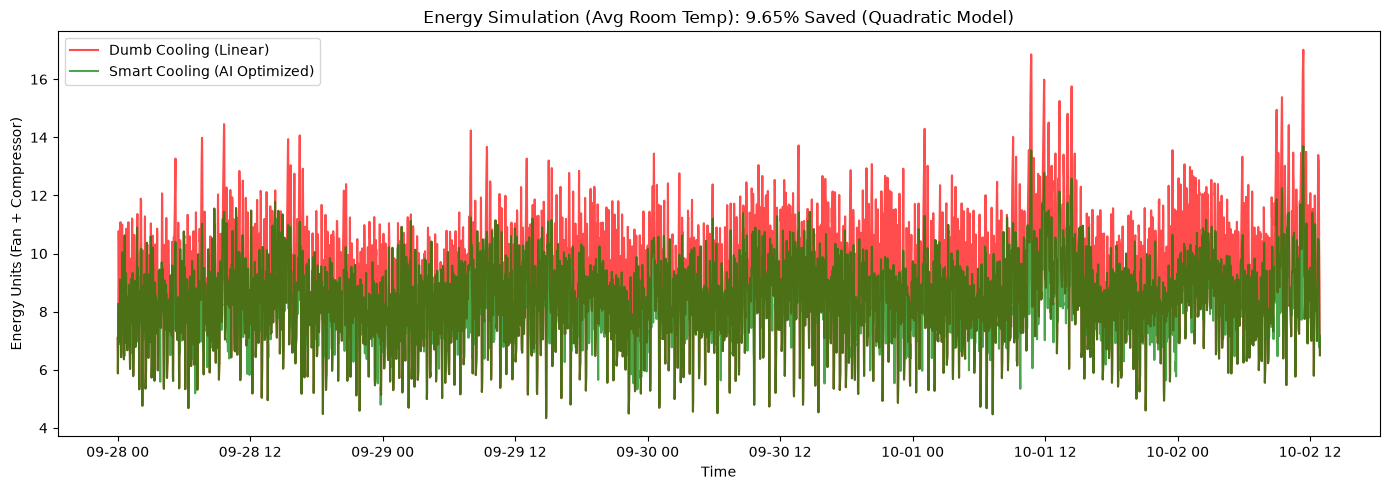

In [ ]:
split_date = pd.to_datetime('2024-09-28')
train = df_clean[df_clean['time'] < split_date]
test  = df_clean[df_clean['time'] >= split_date]

features = ['power_1', 'power_2', 'power_3', 'hour', 'minute', 'regime', 
            'temp_lag_1m', 'temp_lag_5m', 'temp_lag_15m', 'temp_lag_60m', 
            'power_1_lag_1m', 'power_1_lag_5m', 'temp_rolling_mean_15m']

X_train, y_train = train[features], train['temp_target_60m']
X_test, y_test = test[features], test['temp_target_60m']

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=7, random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# --- EVALUATE ---
mae = mean_absolute_error(y_test, predictions)
baseline_mae = mean_absolute_error(y_test, test['temp'])
print(f"Avg Room 60-Min MAE: {mae:.3f} °C")
print(f"Avg Room Baseline MAE: {baseline_mae:.3f} °C")

# --- INDUSTRY-STYLE NON-LINEAR ENERGY SIMULATION ---
# Explanation: In real HVAC systems, energy does not scale linearly with temperature. 
# Fans always consume a base power (base_fan_power). 
# The compressor works exponentially harder (squared) the further the temperature is from the target.

results = pd.DataFrame({
    'time': test['time'].values,
    'actual_temp': y_test.values,
    'predicted_temp': predictions
})

base_fan_power = 1.5 
baseline_energy_list = []
smart_energy_list = []

for i in range(len(results)):
    actual = results['actual_temp'].iloc[i]
    predicted = results['predicted_temp'].iloc[i]
    
    # 1. Baseline Energy: Strict 22.0°C target with a quadratic penalty
    diff_base = max(0.0, actual - 22.0) # comparing with 0.0 in case the room is cooler than 22.0°C, we dont take a negative energy penalty that confuses the model and evrth
    baseline_energy = base_fan_power + (diff_base ** 2) * 0.8
    baseline_energy_list.append(baseline_energy)
    
    # 2. Smart Relax Target: 22.5°C if safe, else 22.0°C
    # If the AI predicts the room will cool down naturally, we relax the target to save energy.
    if predicted < actual:
        current_target = 22.5
    else:
        current_target = 22.0
        
    # 3. Smart Energy: Calculated with the relaxed target
    diff_smart = max(0.0, actual - current_target)
    smart_energy = base_fan_power + (diff_smart ** 2) * 0.8
    smart_energy_list.append(smart_energy)

results['baseline_energy'] = baseline_energy_list
results['smart_energy'] = smart_energy_list

baseline_total = sum(baseline_energy_list)
smart_total = sum(smart_energy_list)
savings = ((baseline_total - smart_total) / baseline_total) * 100

print(f"NEW Energy Saved (Realistic Physics): {savings:.2f}%")

# --- PLOT ---
plt.figure(figsize=(14, 5))
plt.plot(results['time'], results['baseline_energy'], label='Dumb Cooling (Linear)', color='red', alpha=0.7)
plt.plot(results['time'], results['smart_energy'], label='Smart Cooling (AI Optimized)', color='green', alpha=0.7)
plt.title(f'Energy Simulation (Avg Room Temp): {savings:.2f}% Saved (Quadratic Model)')
plt.ylabel('Energy Units (Fan + Compressor)')
plt.xlabel('Time')
plt.legend()
plt.tight_layout()
plt.savefig(r"D:\Projects\datacenter-efficiencyDMP\reports\figures\07_avg_room_energy.png", dpi=150)
plt.show()